# Comparing BTC, ETH and SOL prices

Compare the three markets at a **daily** frequency. The ETH and SOL tables used here contain daily observations; hourly values cannot be reconstructed from them. BTC is aggregated from minute data. Set `BTC_DATA_PATH` to `btcusd_1-min_data.csv` or put that file in this directory.

Sources: [Bitcoin Historical Data](https://www.kaggle.com/datasets/mczielinski/bitcoin-historical-data) and [Solana historical data](https://www.kaggle.com/datasets/craigdagama/solana-historical-data). The original local ETH table covers 2022-06-09 to 2025-06-09. The earlier SOL file was an identical copy of the ETH data; it has been replaced with real SOL observations. BTC updates over time, but this comparison uses the overlapping dates.

This is descriptive analysis. Price-level correlations can reflect shared trends; returns and lagged correlations do not establish causation or trading performance.

**Data:** [Bitcoin Historical Data](https://www.kaggle.com/datasets/mczielinski/bitcoin-historical-data) and [Solana Historical Data](https://www.kaggle.com/datasets/craigdagama/solana-historical-data). Set `BTC_DATA_PATH` or place `btcusd_1-min_data.csv` here; put the SOL CSV at `solana-historical-data.csv`. The ETH input is the original local `ethereum-historical-data.csv`; its exact public source has not been confirmed and it must be supplied separately.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

btc_path = os.environ.get('BTC_DATA_PATH', 'btcusd_1-min_data.csv')
btc = pd.read_csv(btc_path, usecols=['Timestamp', 'Close'], dtype={'Timestamp': 'int64', 'Close': 'float32'})
btc['date'] = pd.to_datetime(btc['Timestamp'], unit='s', utc=True).dt.tz_localize(None)
btc = btc.set_index('date')['Close'].sort_index().resample('D').last().dropna()

eth = pd.read_csv('ethereum-historical-data.csv')
eth['date'] = pd.to_datetime(eth['Дата'])
eth['close'] = pd.to_numeric(eth['Закрыть'].str.replace(r'[$,]', '', regex=True))
eth = eth.set_index('date')['close'].sort_index()

sol = pd.read_csv('solana-historical-data.csv')
sol['date'] = pd.to_datetime(sol['Day'], format='%d/%m/%Y')
sol = sol.set_index('date')['Close'].sort_index()

prices = pd.concat([btc.rename('BTC'), eth.rename('ETH'), sol.rename('SOL')], axis=1, join='inner').dropna()
assert len(prices) > 14 and prices.index.is_unique
print(f'Overlapping daily observations: {len(prices)}')
print(f'Period: {prices.index.min().date()} to {prices.index.max().date()}')
print(prices.head().round(2))

Overlapping daily observations: 1097
Period: 2022-06-09 to 2025-06-09
                     BTC     ETH    SOL
date                                   
2022-06-09  30089.029297  1786.0  39.93
2022-06-10  29065.660156  1658.0  37.08
2022-06-11  28390.939453  1524.0  33.96
2022-06-12  26585.099609  1439.0  30.64
2022-06-13  22450.429688  1199.0  27.70


## Prices and weekly decomposition

Prices use separate axes because their USD scales differ. The decomposition is exploratory and uses a seven-day period.

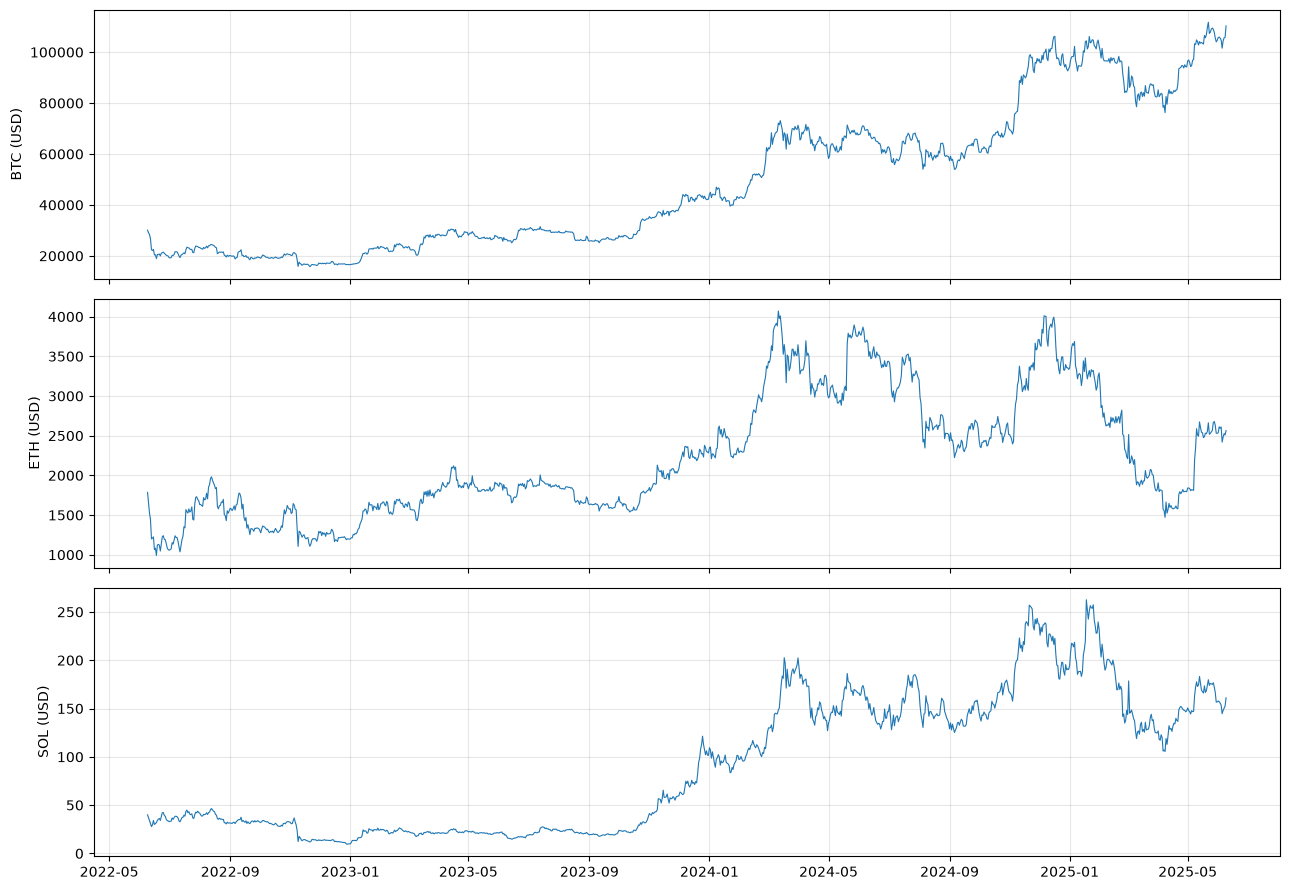

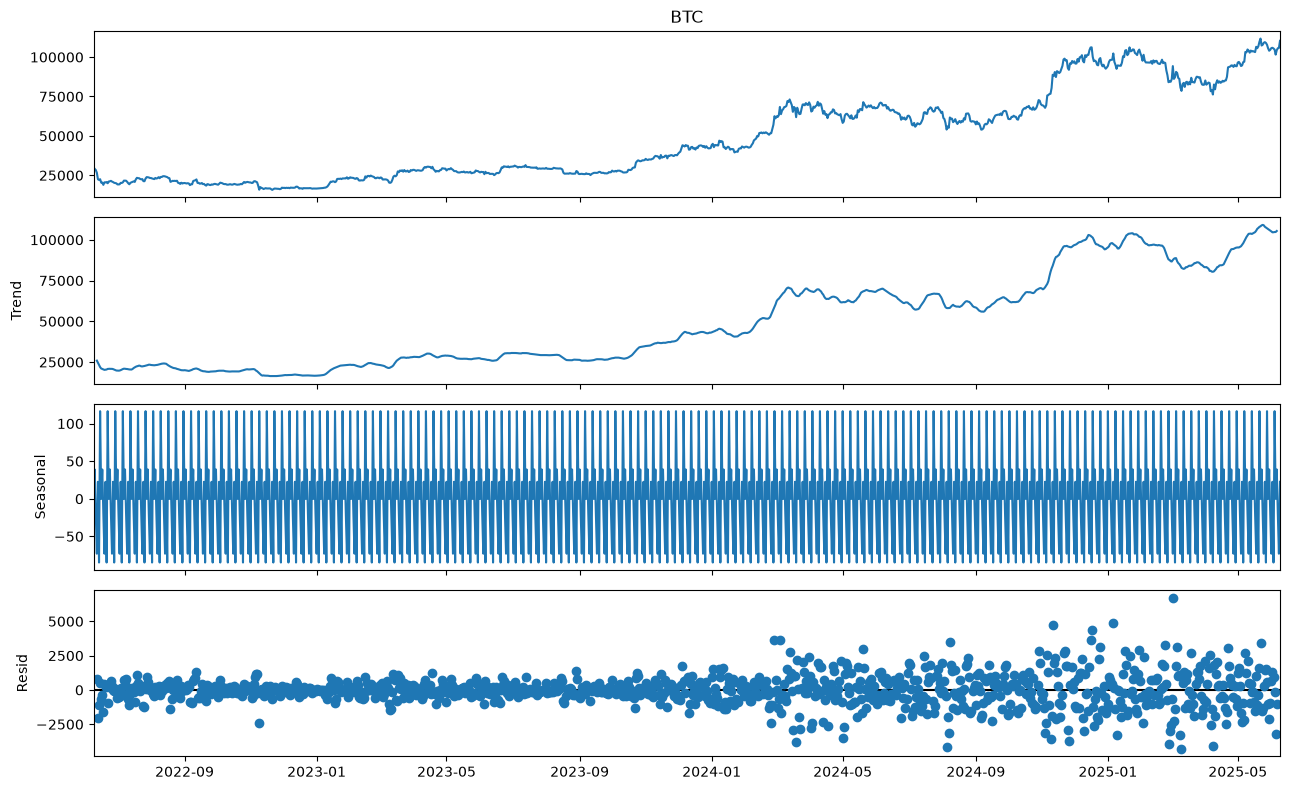

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, name in zip(axes, prices.columns):
    ax.plot(prices.index, prices[name], linewidth=0.8)
    ax.set_ylabel(f'{name} (USD)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig = seasonal_decompose(prices['BTC'], model='additive', period=7).plot()
fig.set_size_inches(13, 8)
plt.tight_layout()
plt.show()

## Correlations and lagged daily returns

The lag chart compares each day’s SOL return with BTC returns from up to 14 days earlier.

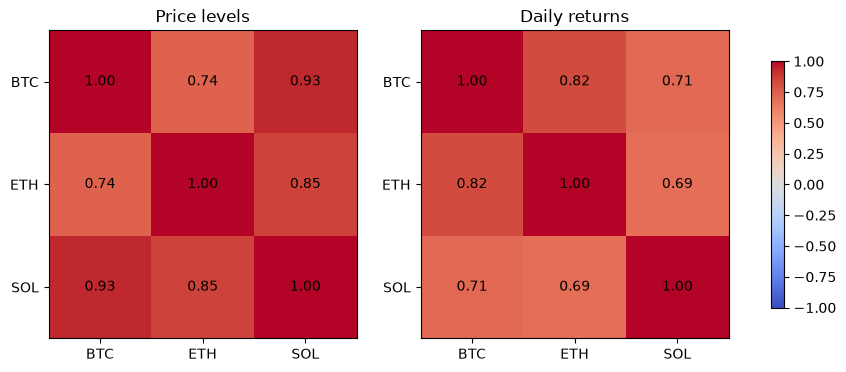

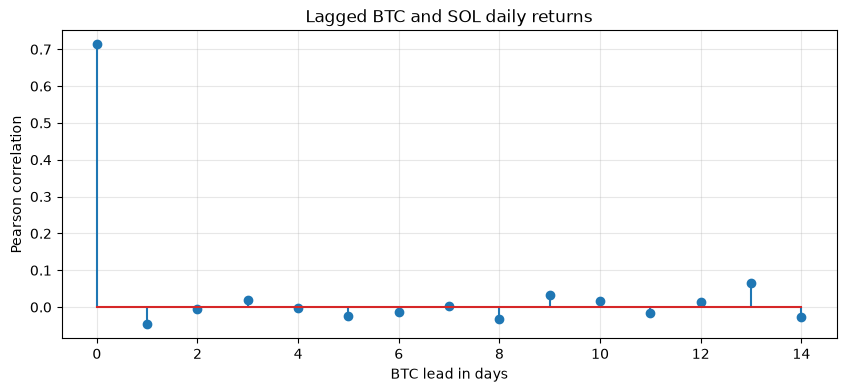

Daily return correlations:
       BTC    ETH    SOL
BTC  1.000  0.823  0.713
ETH  0.823  1.000  0.694
SOL  0.713  0.694  1.000


In [3]:
returns = prices.pct_change().dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, title in zip(axes, [prices, returns], ['Price levels', 'Daily returns']):
    corr = data.corr()
    image = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=corr.columns, yticklabels=corr.columns, title=title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()

lags = np.arange(15)
correlations = [returns['BTC'].shift(int(lag)).corr(returns['SOL']) for lag in lags]
fig, ax = plt.subplots(figsize=(10, 4))
ax.stem(lags, correlations)
ax.set(xlabel='BTC lead in days', ylabel='Pearson correlation', title='Lagged BTC and SOL daily returns')
ax.grid(alpha=0.3)
plt.show()
print('Daily return correlations:')
print(returns.corr().round(3))